The following runs inside the BenchMAX environment.

# Simple training and evaluation on Rock-Paper-Scissors

## Explore the game

In [1]:
from benchmax import load_game

game = load_game("rock_paper_scissors")

env = game.new_env()
time_step = env.reset()

print("Game name:", game.name, "\nGame players:", game.players, "\n")

print("Observations:", time_step.observations)
print("Legal actions:", time_step.legal_actions[0], "\n") # 0 = rock; 1 = paper; 2 = scissors

# player 0 plays rock; player 1 plays scissors -> player 0 wins
time_step = env.step({0: 0, 1: 2})
print("Rock vs. Scissors:", time_step.rewards, "\nTerminated:", time_step.terminated)

Game name: rock_paper_scissors 
Game players: (0, 1) 

Observations: {0: (0.0,), 1: (0.0,)}
Legal actions: (0, 1, 2) 

Rock vs. Scissors: {0: 1.0, 1: -1.0} 
Terminated: True


## Why measure exploitability?

Give both players the same strategy: start with uniform play, then increasingly favor rock.
Their self-play returns stay zero, even when both always play rock. But an opponent can
exploit that predictability by switching to paper.

For rock bias $b$, use probabilities $((1+2b)/3, (1-b)/3, (1-b)/3)$.
Each player can improve its payoff by $b$ through a unilateral switch to paper.
NashConv sums those gains; exploitability is half that sum in this two-player zero-sum game.

In [2]:
import numpy as np

print("Rock bias | Self-play return | Exploitability")
for bias in (0.0, 0.5, 1.0):
    probabilities = np.array([(1 + 2 * bias) / 3, (1 - bias) / 3, (1 - bias) / 3])

    def biased_profile(player, observations, action_space, legal_mask, probabilities=probabilities):
        return np.broadcast_to(probabilities, legal_mask.shape)

    metrics = game.evaluate(biased_profile)
    print(f"{bias:9.1f} | {metrics['expected_returns'][0]:16.2f} | {metrics['exploitability']:14.2f}")

Rock bias | Self-play return | Exploitability
      0.0 |             0.00 |           0.00
      0.5 |             0.00 |           0.50
      1.0 |             0.00 |           1.00


## Train with regret matching

Recover the payoff matrix through environment steps, then train both players in self-play.

In [3]:
def payoff_matrix(game):
    actions = game.action_spaces[0]
    payoff = np.empty((len(actions), len(actions)))
    for row, action_0 in enumerate(actions):
        for column, action_1 in enumerate(actions):
            env = game.new_env()
            time_step = env.reset()
            time_step = env.step({0: action_0, 1: action_1})
            payoff[row, column] = time_step.rewards[0]
    return payoff


def strategy_from_regrets(regrets):
    positive = np.maximum(regrets, 0.0)
    return positive / positive.sum() if positive.any() else np.full(3, 1 / 3)


def train(game, iterations=5_000):
    payoff = payoff_matrix(game)
    regrets = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
    strategy_sum = np.zeros_like(regrets)
    exploitability = []

    for iteration in range(1, iterations + 1):
        strategies = np.vstack([strategy_from_regrets(row) for row in regrets])
        strategy_sum += strategies
        action_values = np.vstack([payoff @ strategies[1], -payoff.T @ strategies[0]])
        regrets += action_values - np.sum(strategies * action_values, axis=1, keepdims=True)

        average = strategy_sum / iteration

        # Fix this iteration's average strategy for all evaluation queries.
        def policy_profile(player, observations, action_space, legal_mask, average=average):
            return np.broadcast_to(average[player], legal_mask.shape)

        exploitability.append(
            game.evaluate(policy_profile)["exploitability"]
        )

    return strategy_sum / iterations, np.asarray(exploitability), payoff

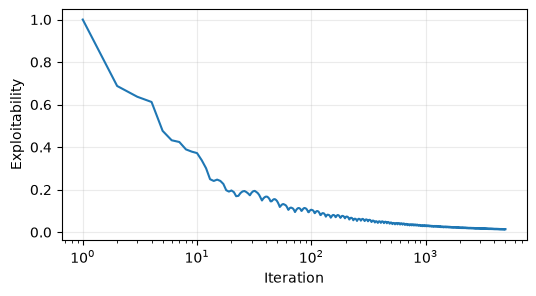

In [4]:
import matplotlib.pyplot as plt

strategies, exploitability, payoff = train(game)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(exploitability) + 1), exploitability)
ax.set(xscale="log", xlabel="Iteration", ylabel="Exploitability")
ax.grid(alpha=0.25)
plt.show()

## Evaluate the trained policy profile

In [5]:
action_names = ("rock", "paper", "scissors")


# All three RPS actions are legal; columns follow rock, paper, scissors.
def policy_profile(player, observations, action_space, legal_mask):
    return np.broadcast_to(strategies[player], legal_mask.shape)


for player, strategy in enumerate(strategies):
    print(f"player {player}:", dict(zip(action_names, strategy.round(3))))

game.evaluate(policy_profile)

player 0: {'rock': np.float64(0.34), 'paper': np.float64(0.336), 'scissors': np.float64(0.324)}
player 1: {'rock': np.float64(0.33), 'paper': np.float64(0.328), 'scissors': np.float64(0.341)}


{'player_improvements': {0: 0.013081804583893165, 1: 0.015473417827798062},
 'nash_gap': 0.015473417827798062,
 'nash_conv': 0.028555222411691228,
 'expected_returns': {0: 7.225344186308994e-05, 1: -7.225344186308951e-05},
 'exploitability': 0.014277611205845614}